# 07 · Kaynak tahmini, hata yayılımı ve yol haritası
*Makale: Bölüm 3, Şekil 4a–c ve Sonuçlar.*

Bu notebook üç soruyu yanıtlıyor:
1. Aktif uzay büyüdükçe kuantum bilgisayar için kaç qubit ve kaç kapı gerekiyor?
2. Kuantum enerjilerinin hatası ΔG'yi ne kadar etkiliyor? (Kuantum bilgisayarın ne kadar *doğru* olması gerekiyor?)
3. Ölçtüğümüz sürelere göre gerçek projede **nerede HPC, nerede kuantum bilgisayar** gerekecek?

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import qmmm, quantum, ml
pools = {leg: (lambda d: (d["X"], d["B"]))(store.load_npz(f"pool_{leg}.npz")) for leg in ["complex", "solvent"]}
regions = {leg: qmmm.QMRegion(leg) for leg in pools}
fr = regions["complex"].frame(pools["complex"][0][0], pools["complex"][1][0])
mf = qmmm.hf_in_field(fr, regions["complex"].guest_symbols())
with store.timed("07_kaynak_tahmini"):
    rs = quantum.resource_estimates(mf, config.P()["resource_scan"])
store.save_json("quantum.json", {"resources": rs})
for r in rs:
    print(f"{r['n_orb']:2d} orbital | {r['n_qubits']:2d} qubit | {r['n_pauli_terms']:6d} Pauli terimi | λ={r['lambda_ha']:7.1f} Ha | "
          f"qubitization ~{r['qubitization_toffoli_naive']:.1e} Toffoli | qDRIFT ~{r['qdrift_exponentials']:.1e} üstel")

[süre] 07_kaynak_tahmini: 3.5 s
 2 orbital |  4 qubit |     26 Pauli terimi | λ=    0.8 Ha | qubitization ~2.1e+04 Toffoli | qDRIFT ~2.5e+06 üstel
 4 orbital |  8 qubit |    360 Pauli terimi | λ=    2.8 Ha | qubitization ~1.0e+06 Toffoli | qDRIFT ~3.1e+07 üstel
 6 orbital | 12 qubit |   1818 Pauli terimi | λ=    6.5 Ha | qubitization ~1.2e+07 Toffoli | qDRIFT ~1.6e+08 üstel
 8 orbital | 16 qubit |   5792 Pauli terimi | λ=   13.1 Ha | qubitization ~7.4e+07 Toffoli | qDRIFT ~6.6e+08 üstel


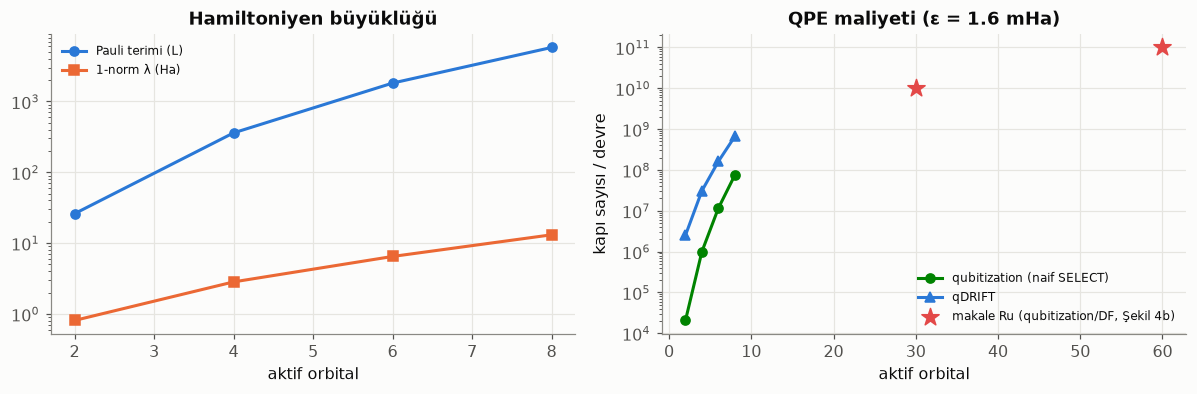

In [3]:
n = np.array([r["n_orb"] for r in rs])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7))
axs[0].semilogy(n, [r["n_pauli_terms"] for r in rs], marker="o", color=C["blue"], label="Pauli terimi (L)")
axs[0].semilogy(n, [r["lambda_ha"] for r in rs], marker="s", color=C["orange"], label="1-norm λ (Ha)")
axs[0].set_xlabel("aktif orbital"); axs[0].set_title("Hamiltoniyen büyüklüğü"); axs[0].legend(fontsize=8)
axs[1].semilogy(n, [r["qubitization_toffoli_naive"] for r in rs], marker="o", color=C["green"], label="qubitization (naif SELECT)")
axs[1].semilogy(n, [r["qdrift_exponentials"] for r in rs], marker="^", color=C["blue"], label="qDRIFT")
# Makaledeki (Şekil 4b) Ru sistemi için okunan kaba değerler, kıyas için:
axs[1].scatter([30, 60], [1e10, 1e11], marker="*", s=140, color=C["red"], zorder=5, label="makale Ru (qubitization/DF, Şekil 4b)")
axs[1].set_xlabel("aktif orbital"); axs[1].set_ylabel("kapı sayısı / devre"); axs[1].set_title("QPE maliyeti (ε = 1.6 mHa)")
axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Okuma:** Bizim formüllerimiz yalnızca **mertebe** veriyor. Makaledeki "double factorization" gibi teknikler
sayıları birkaç mertebe azaltıyor. Yine de mesaj aynı: ~30–60 orbitallik ilginç bir çekirdek için
**~100–1000 mantıksal qubit ve 10¹⁰ civarı kapı** gerekiyor. Bu ancak hata düzeltmeli, hızlı
(kapı başına ≲10⁻⁷ s) bir makineyle mümkün (makale Bölüm 3).

### Kuantum enerjilerinin hatası ΔG'ye nasıl yansıyor?
Yüksek seviye enerjilere (gelecekte kuantum bilgisayardan gelecek) σ büyüklüğünde rastgele hata
ekliyoruz, ML2'yi yeniden eğitiyoruz ve ΔG'nin ne kadar saptığına bakıyoruz.

[süre] 07_hata_yayilimi: 2.5 s


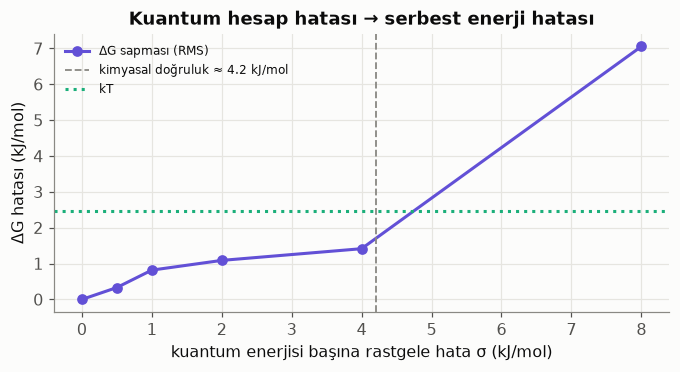

PosixPath('/home/claude/qb/results/test/results.json')

In [4]:
lab = qmmm.Labeler(regions, pools); lab.load_dict(store.load_json("labels.json"))
feats = {leg: ml.descriptors(regions[leg], *pools[leg]) for leg in pools}
train1 = [tuple(t) for t in store.load_json("ml1.json")["train"]]
ml2_set = [tuple(t) for t in store.load_json("ml2.json")["train"]]
model1 = ml.GPModel().fit(np.array([feats[l][i] for l, i in train1]), np.array([lab.dU_dft(l, i) for l, i in train1]))
base1 = {leg: model1.predict(feats[leg]) for leg in pools}
delta = np.array([lab.high_minus_dft(l, i) for l, i in ml2_set])
F2 = np.array([feats[l][i] for l, i in ml2_set])

def dG_corr(d):
    m2 = ml.GPModel(seed=1).fit(F2, d)
    return ml.binding_correction(base1["complex"] + m2.predict(feats["complex"]),
                                 base1["solvent"] + m2.predict(feats["solvent"]))["cumulant"]

ref = dG_corr(delta)
sigmas = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0]
rng = np.random.default_rng(0)
spread = []
with store.timed("07_hata_yayilimi"):
    for s in sigmas:
        vals = [dG_corr(delta + rng.normal(0, s, len(delta))) for _ in range(8 if s > 0 else 1)]
        spread.append(np.sqrt(np.mean((np.array(vals) - ref) ** 2)))
fig, ax = plt.subplots(figsize=(6.3, 3.5))
ax.plot(sigmas, spread, marker="o", color=C["violet"], label="ΔG sapması (RMS)")
ax.axvline(1.6e-3 * config.HARTREE_TO_KJ, color=C["muted"], ls="--", lw=1.2, label="kimyasal doğruluk ≈ 4.2 kJ/mol")
ax.axhline(config.KT, color=C["aqua"], ls=":", label="kT")
ax.set_xlabel("kuantum enerjisi başına rastgele hata σ (kJ/mol)"); ax.set_ylabel("ΔG hatası (kJ/mol)")
ax.set_title("Kuantum hesap hatası → serbest enerji hatası"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
store.save_json("results.json", {"noise_propagation": {"sigma": sigmas, "dG_rms": spread}})

**Yorum:** Rastgele hatalar ML ve ortalama alma sayesinde kısmen sönümleniyor. **Sistematik** hatalar
(örneğin yetersiz aktif uzay ya da kötü başlangıç durumu) ise sönümlenmiyor. Makalenin "kimyasal doğruluk
(~1 kJ/mol bölgesi)" hedefi bu yüzden konuluyor. Eğitim noktası azsa ML2 hatayı büyütebiliyor da.

### Sonuçların özeti

MM (FEP)                  -31.95 ± 4.72 kJ/mol
MM + ML1 (QM/MM, DFT)     -33.82 ± 4.77 kJ/mol
MM + ML2 (QM/QM/MM)       -32.50 ± 4.78 kJ/mol
Deney                     -12.76 ± 0.04 kJ/mol


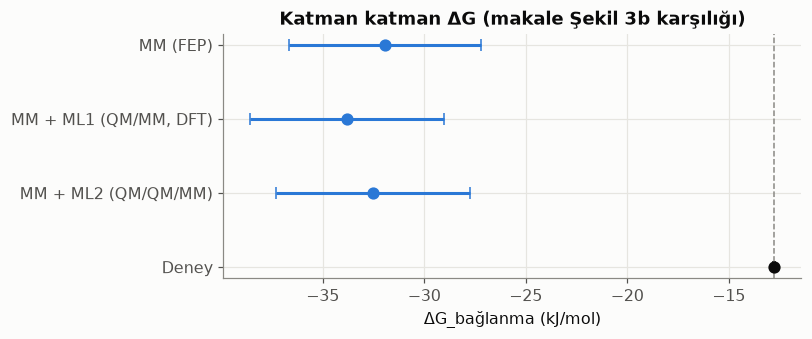

In [5]:
r = store.load_json("results.json")
rows = [("MM (FEP)", r["dG_MM"]["dG_bind"], r["dG_MM"]["dG_bind_err"]),
        ("MM + ML1 (QM/MM, DFT)", r.get("dG_MM_ML1"), r.get("dG_MM_ML1_err")),
        ("MM + ML2 (QM/QM/MM)", r.get("dG_MM_ML2"), r.get("dG_MM_ML2_err")),
        ("Deney", r["exp_dG_kJ"], r["exp_dG_err_kJ"])]
for name, v, e in rows:
    print(f"{name:24s} {v:7.2f} ± {e:.2f} kJ/mol")
fig, ax = plt.subplots(figsize=(7.5, 3.2))
cols = [C["blue"], C["blue"], C["blue"], C["ink"]]
for k, (name, v, e) in enumerate(rows):
    ax.errorbar(v, k, xerr=e, fmt="o", color=cols[k], ms=7, capsize=4)
ax.axvline(r["exp_dG_kJ"], color=C["muted"], ls="--", lw=1)
ax.set_yticks(range(len(rows)), [x[0] for x in rows]); ax.invert_yaxis()
ax.set_xlabel("ΔG_bağlanma (kJ/mol)"); ax.set_title("Katman katman ΔG (makale Şekil 3b karşılığı)")
plt.tight_layout(); plt.show()

### Nerede HPC, nerede kuantum bilgisayar? (ölçülen sürelerden ölçekleme)
Bu demoda ölçtüğümüz süreleri, makaledeki gerçek sistemin boyutuna ölçekliyoruz. DFT maliyeti
yaklaşık olarak (baz fonksiyonu)³ ile büyüyor; Ru ilacı NKP1339'un baz fonksiyonu sayısını PySCF'le sayıyoruz.

In [6]:
from pyscf import gto
t = store.load_json("timings.json")
lab_t = store.load_json("labels.json")["timings"]
t_dft, t_high = float(np.mean(lab_t["dft"])), float(np.mean(lab_t["high"]))
nb_ours = r["qm_nbasis"]
# NKP1339 anyonu [RuCl4(indazol)2]^-  : C14 H12 N4 Cl4 Ru  (baz sayısı geometriden bağımsız)
atoms = ["Ru"] + ["Cl"] * 4 + ["N"] * 4 + ["C"] * 14 + ["H"] * 12
mol = gto.M(atom=[(a, (0, 0, 5.0 * k)) for k, a in enumerate(atoms)], basis="def2-svp",
            ecp={"Ru": "def2-svp"}, charge=-1, spin=1, verbose=0)
nb_ru = mol.nao
scale = (nb_ru / nb_ours) ** 3
ns_day = r.get("md_ns_per_day", float("nan"))
fep_ns_paper = 2 * 20 * 5      # 2 bacak × ~20 λ × ~5 ns (tipik protein-ligand FEP)
tab = [
    ("MM-FEP (protein, ~50k atom)", f"{fep_ns_paper} ns MD", f"{fep_ns_paper/ max(ns_day,1e-9) * 10:.1f} gün (bu makinede, 10× büyük sistem)", "GPU kümesi"),
    ("QM/MM DFT, ~2000 yapı", f"{t_dft:.0f} s/yapı ({r.get('n_threads', 1)} çekirdek)", f"~{2000 * t_dft * scale * r.get('n_threads', 1) / 3600:,.0f} çekirdek-saat (Ru ölçekli)", "HPC (CPU)"),
    ("QM/QM/MM, ~10000 yapı", f"{t_high:.0f} s/yapı ({r.get('n_threads', 1)} çekirdek)", f"≥{10000 * t_high * scale * r.get('n_threads', 1) / 3600:,.0f} çekirdek-saat (DMRG çok daha pahalı)", "HPC → kuantum bilgisayar"),
    ("Kuantum çekirdek ≥ 30 orbital", "klasik FCI imkânsız", "—", "Hata düzeltmeli kuantum bilgisayar"),
]
print(f"Baz fonksiyonu: bizim misafir {nb_ours}, NKP1339 {nb_ru}  → DFT maliyet çarpanı ~{scale:.0f}×\n")
print(f"{'Adım':34s} | {'Ölçülen':22s} | {'Gerçek projeye ölçekli':44s} | Nerede")
print("-" * 130)
for row in tab:
    print(f"{row[0]:34s} | {row[1]:22s} | {row[2]:44s} | {row[3]}")

Baz fonksiyonu: bizim misafir 134, NKP1339 415  → DFT maliyet çarpanı ~30×

Adım                               | Ölçülen                | Gerçek projeye ölçekli                       | Nerede
----------------------------------------------------------------------------------------------------------------------------------
MM-FEP (protein, ~50k atom)        | 200 ns MD              | 63.6 gün (bu makinede, 10× büyük sistem)     | GPU kümesi
QM/MM DFT, ~2000 yapı              | 29 s/yapı (2 çekirdek) | ~971 çekirdek-saat (Ru ölçekli)              | HPC (CPU)
QM/QM/MM, ~10000 yapı              | 12 s/yapı (2 çekirdek) | ≥1,984 çekirdek-saat (DMRG çok daha pahalı)  | HPC → kuantum bilgisayar
Kuantum çekirdek ≥ 30 orbital      | klasik FCI imkânsız    | —                                            | Hata düzeltmeli kuantum bilgisayar


## Ekip için yol haritası (özet)

| Aşama | Laptop (bu demo) | HPC gerektiğinde | Kuantum bilgisayar gerektiğinde |
|---|---|---|---|
| Sistem hazırlama, MM-FEP | ✓ küçük konakçı–misafir | Protein–ligand, çok sayıda ligand | — |
| QM/MM etiketleri (DFT) | Onlarca, ≤ ~30 atomluk QM bölgesi | Binlerce, metal içeren bölge | — |
| ML1/ML2 eğitimi | GP, yüzlerce nokta | Sinir ağı potansiyeli, GPU | — |
| Kuantum çekirdek (CASCI) | ≤ ~16 orbital (tam FCI) | DMRG ile ~30–60 orbital | ≥ 30–60 orbital, binlerce yapı, her biri ≤ 20 dk |
| QPE/VQE denemeleri | Simülatör ≤ ~24 qubit | GPU statevector ≤ ~36 qubit (makale ref. 30) | Gerçek donanım: küçük demo (IBM, 4–8 qubit); asıl hedef hata düzeltmeli makine |

**Sonraki adımlar için öneriler:**
1. `demo` ön ayarını GPU'da çalıştırıp sonuçları birlikte yorumlayın.
2. Misafiri değiştirin (ör. guest 5 sikloheptanol, guest 4 trans-4-metilsiklohekzanol) ve deneyle korelasyona bakın.
3. Açık kabuklu bir metal kompleksine geçmek: asıl kuantum avantajı sorusu orada başlıyor (makalenin Ru örneği).
4. HPC başvurusunda (UHeM öğrenci projesi) 03–05 adımlarının ölçeklenmiş versiyonunu proje olarak tanımlayın.